<a href="https://colab.research.google.com/github/MJMortensonWarwick/AnalyticsEngineering2026/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "./content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "./content/bikes.zip")
    zipfile.ZipFile("./content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}
tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id                 str
bike_id                 str
start_station_id        str
end_station_id          str
start_time              str
duration_min        float64
user_type               str
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## 1. Look at the data

*What does one row of each table represent? Which columns will you use? What looks odd, missing or inconsistent? Write down what you find.*

In [4]:

for key, val in tables.items():
    print(f"========= {key} =========")
    display(val.head(3))
# It looks like in order to answer this question we need a table which is bike_type, trip_length and zone
# I believe it is best to get this from trips 

========= trips =========


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual


========= bikes =========


,bike_id,bike_type,purchase_year
0,B001,Standard,2021
1,B002,Electric,2022
2,B003,electric,2024


========= stations =========


,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0


## 2. Clean and prepare

*Decide what to do about each problem you found, say why, and do it. Short cells that you can re-run are better than one long cell.*

In [5]:
# Lets get biketype
bikes = tables["bikes"].copy()

# No duplicates or missing
duplicate_ids = bikes[
    bikes.duplicated(subset=["bike_id"], keep=False)
    ].sort_values(by="bike_id")
display(duplicate_ids)
print(f"Num Missing {bikes["bike_id"].isna().sum()}")



,bike_id,bike_type,purchase_year


Num Missing 0


In [6]:
# Not missing any just non standard
print(f"Unique Values {list(bikes["bike_type"].unique())}")
bikes["bike_type"] = (
    bikes["bike_type"]
    .str.replace(r'[\s|_]+', ' ', regex=True)
    .str.strip()
    .str.title()
    )
print(f"Unique Values {list(bikes["bike_type"].unique())}")
# Now we have the unique values we can add column for is_electric
bikes["is_electric"] = bikes["bike_type"] == "Standard"
# Looks like its working you can see Standard true and electric and e-bike false
display(bikes)

Unique Values ['Standard', 'Electric ', 'electric', 'STANDARD', 'standard', 'Electric', 'E-bike']
Unique Values ['Standard', 'Electric', 'E-Bike']


,bike_id,bike_type,purchase_year,is_electric
0,B001,Standard,2021,True
1,B002,Electric,2022,False
2,B003,Electric,2024,False
3,B004,Standard,2021,True
4,B005,Standard,2022,True
5,B006,Standard,2024,True
6,B007,Standard,2024,True
7,B008,Standard,2021,True
8,B009,Standard,2021,True
9,B010,Standard,2023,True


In [7]:
# Now lets look at stations check ids are correct and sensible zones
stations = tables["stations"].copy()
display(stations)
# As its such a small table we can just see that its not missing any ids and has no duplicates, long term this should be properly checked. 
# Same with zones

,station_id,station_name,zone,capacity
0,S01,Market Square,Centre,29.0
1,S02,Railway Station,Centre,23.0
2,S03,Canal Basin,North,24.0
3,S04,University Gate,West,28.0
4,S05,Park Road,South,22.0
5,S06,Library Corner,Centre,26.0
6,S07,Hospital Entrance,East,27.0
7,S08,Riverside Walk,South,14.0
8,S09,Old Town Hall,Centre,NaN
9,S10,Retail Park,North,16.0


In [8]:
# Lets look at the trips
trips = tables["trips"].copy()
# There are some with duplicate ids but they seem to be complete duplicates
duplicate_ids = trips[
    trips.duplicated(subset=["trip_id"], keep=False)
    ].sort_values(by="trip_id")
display(duplicate_ids)
trips = trips.drop_duplicates()


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
96,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
97,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
175,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
176,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
185,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
186,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
285,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
286,T0283,B014,S07,S04,2025-03-15 19:48:00,5.0,Member
326,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member
327,T0323,B023,S08,S05,2025-03-17 17:17:00,52.0,Member


In [9]:
# Dropping all complete duplicates works (row wide) no missing either
trips = trips.drop_duplicates()
duplicate_ids = trips[
    trips.duplicated(subset=["trip_id"], keep=False)
    ].sort_values(by="trip_id")
display(duplicate_ids)

print(f"Num Missing {trips["trip_id"].isna().sum()}")

,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type


Num Missing 0


In [10]:
# Lets work on adding the bike_type to the trips list

# Check that all the bike ids are valid (no the bikes table)
print(f"Invalid bike ids: {trips.shape[0] - trips["bike_id"].isin(bikes["bike_id"]).sum()}")
# they all are so lets map them (bike_type as well so we can make sure it works)
trips = trips.merge(bikes[["bike_id", "bike_type", "is_electric"]], on="bike_id", how="left")
# Nothing went wrong still the same number of rows
print(f"Num rows trips: {trips.shape[0]}")
# Its works
print(f"Unique bike types {list(trips["bike_type"].unique())}")




Invalid bike ids: 0
Num rows trips: 600
Unique bike types ['Standard', 'Electric', 'E-Bike']


In [11]:
# Now the zone to trip list
# No bad station ids
print(f"Invalid station ids: {trips.shape[0] - trips["start_station_id"].isin(stations["station_id"]).sum()}") 
trips = trips.merge(stations[["station_id", "zone"]], left_on="start_station_id", right_on="station_id", how="left")
print(f"Unique stations {list(trips["zone"].unique())}")
# It works

Invalid station ids: 0
Unique stations ['South', 'Centre', 'West', 'North', 'East']


In [12]:
# Lets work on durations
!pip install matplotlib --quiet
import matplotlib.pyplot as plt

# Some missing durations
print(f"Missing durations {trips["duration_min"].isna().sum()} of {trips.shape[0]}")
display(trips[trips["duration_min"].isna()])
# Nothing really to do but drop its only 5%. Before dropping them lets see what the distrubtion of electric non electric is 



Missing durations 30 of 600


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type,bike_type,is_electric,station_id,zone
12,T0013,B024,S04,S02,01/03/2025 18:43,NaN,Member,Standard,True,S04,West
14,T0015,B040,S03,S04,2025-03-01 19:03:00,NaN,Member,Electric,False,S03,North
30,T0031,B015,S06,S06,2025-03-02 08:50:00,NaN,Casual,Standard,True,S06,Centre
60,T0061,B011,S09,S07,2025-03-04 08:23:00,NaN,Member,Electric,False,S09,Centre
64,T0065,B041,S06,S02,04/03/2025 09:06,NaN,Member,Standard,True,S06,Centre
73,T0074,B016,S06,S02,04/03/2025 17:05,NaN,Member,Standard,True,S06,Centre
86,T0087,B012,S04,S04,2025-03-05 12:27:00,NaN,Casual,Electric,False,S04,West
117,T0118,B025,S06,S12,2025-03-07 06:27:00,NaN,Member,Standard,True,S06,Centre
123,T0124,B036,S01,S06,2025-03-07 08:39:00,NaN,Casual,Electric,False,S01,Centre
145,T0146,B031,S12,S12,2025-03-08 18:45:00,NaN,Member,Standard,True,S12,Centre


In [13]:
# Fairly even. Not much to do so drop na
print(f"Missing electric {trips[trips["is_electric"]]["duration_min"].isna().sum()}. Missing standard: {trips[~trips["is_electric"]]["duration_min"].isna().sum()}")
print(f"Total electric {trips[trips["is_electric"]].shape[0]}. Missing standard: {trips[~trips["is_electric"]].shape[0]}")
trips = trips.dropna(subset="duration_min")
print(f"Missing electric {trips[trips["is_electric"]]["duration_min"].isna().sum()}. Missing standard: {trips[~trips["is_electric"]]["duration_min"].isna().sum()}")
# Worked


Missing electric 17. Missing standard: 13
Total electric 426. Missing standard: 174
Missing electric 0. Missing standard: 0


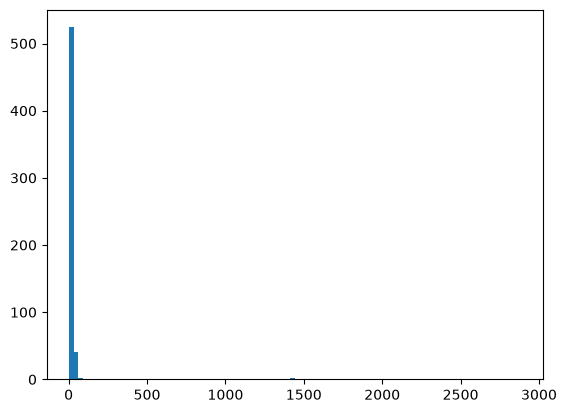

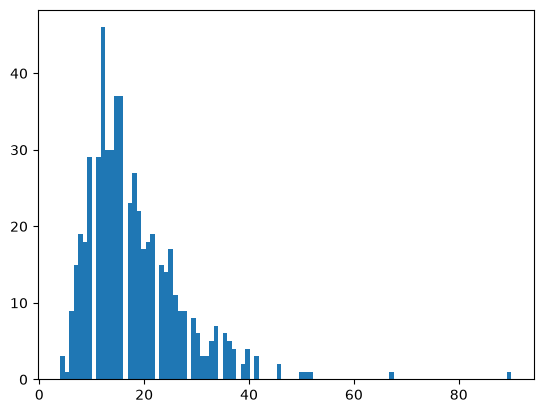

In [14]:

plt.hist(trips["duration_min"], bins=100)
plt.show()
# Some massive outliers to remove let just filter (IQR would be better longer term)
trips = trips[
    trips["duration_min"] < 500
]
plt.hist(trips["duration_min"], bins=100)
plt.show()
# That now seems sensible

In [15]:
# We now have a table of zone trip duration and is electric

display(
    trips.groupby(["is_electric","zone"]).agg(
        mean=("duration_min","mean")
    )
)
# From the graph of duration mins that seems sensible

mean
is_electric zone             
False       Centre  14.506173
            East    15.727273
            North   15.956522
            South   13.416667
            West    15.681818
True        Centre  18.925581
            East    19.500000
            North   20.358974
            South   19.474576
            West    19.821918

## 3. Join and aggregate

*Join the tables and calculate the answer. Note how many rows you expect after each join, then check.*

## 4. Check

*How do you know the answer is right? Compare a count, spot check a few records, or recalculate one number a different way. What did you find?*

## 5. Prompts and AI notes

*Paste each prompt as you sent it. Note what you accepted, changed or rejected and why.*

## 6. What I could not verify

*What remains unchecked? What would you do next?*